<a href="https://colab.research.google.com/github/sahilshirsat2004-coder/CSL701-CE45_Machine-Learning-Lab/blob/main/ML_Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Name :Sahil Ganesh Shirsat
Roll No:CE45

### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.datasets import load_breast_cancer

# Load dataset
cancer = load_breast_cancer()
df = pd.DataFrame(data=cancer.data, columns=cancer.feature_names)
df['diagnosis'] = cancer.target

# Display first 5 rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

Dataset Shape: (569, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-

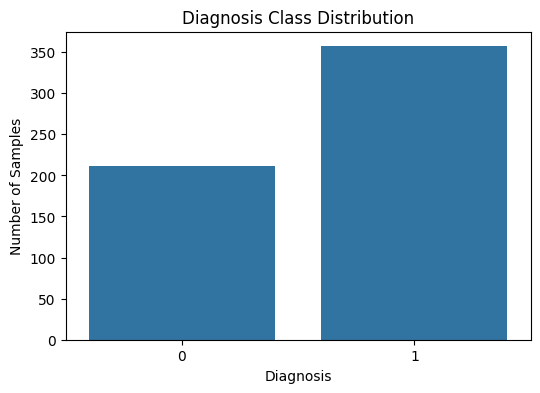

In [ ]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display summary statistics
print("\nSummary Statistics:")
print(df.describe())

# Check diagnosis distribution
print("\nDiagnosis Class Distribution:")
print(df["diagnosis"].value_counts())

# Plot class distribution
plt.figure(figsize=(6, 4))

sns.countplot(x="diagnosis", data=df)

plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.show()

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [ ]:
# Separate features and target
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

# Display first 5 scaled samples
print("\nFirst 5 scaled samples:")
print(X_scaled[:5])

Original feature shape: (569, 30)
Scaled feature shape: (569, 30)

First 5 scaled samples:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.75611957e-0

# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [ ]:
# Calculate pairwise Euclidean distances
distance_matrix = squareform(pdist(X_scaled, metric="euclidean"))

print("Distance Matrix Shape:", distance_matrix.shape)

# Display part of distance matrix
print("\nFirst 5x5 Distance Matrix:")
print(distance_matrix[:5, :5])

# Create complete weighted graph
G = nx.Graph()

# Add nodes
G.add_nodes_from(range(len(X_scaled)))

# Add edges with distance as weight
for i in range(len(X_scaled)):
    for j in range(i + 1, len(X_scaled)):
        G.add_edge(
            i,
            j,
            weight=distance_matrix[i, j]
        )

print("\nNumber of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())

Distance Matrix Shape: (569, 569)

First 5x5 Distance Matrix:
[[ 0.         10.31849715  6.77763352 10.47267382  8.67103637]
 [10.31849715  0.          5.0320153  16.25073886  4.37888839]
 [ 6.77763352  5.0320153   0.         12.84472056  4.46222854]
 [10.47267382 16.25073886 12.84472056  0.         15.37530011]
 [ 8.67103637  4.37888839  4.46222854 15.37530011  0.        ]]

Number of Nodes: 569
Number of Edges: 161596


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [ ]:


# Compute Minimum Spanning Tree
mst_sparse = minimum_spanning_tree(distance_matrix)

# Convert sparse MST to NetworkX graph
mst = nx.from_scipy_sparse_array(mst_sparse)

print("Number of MST Nodes:", mst.number_of_nodes())
print("Number of MST Edges:", mst.number_of_edges())

# Extract MST edges and weights
mst_edges = []

for u, v, data in mst.edges(data=True):
    mst_edges.append((u, v, data["weight"]))

# Convert to DataFrame
mst_edges_df = pd.DataFrame(
    mst_edges,
    columns=["Node1", "Node2", "Weight"]
)

# Sort edges by weight
mst_edges_df = mst_edges_df.sort_values(
    by="Weight",
    ascending=False
)

print("\nMST Edges:")
print(mst_edges_df.head(10))

Number of MST Nodes: 569
Number of MST Edges: 568

MST Edges:
     Node1  Node2     Weight
543    461    503  12.299945
110     68    152  10.476075
192    116    213   8.826434
326    212    461   8.268542
180    108    122   8.077984
5        3    190   7.871039
111     68    376   7.791093
131     78    351   7.089526
298    190    351   7.062630
22      12     42   6.968998


# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [ ]:
# Copy MST
mst_cluster = mst.copy()

# Sort MST edges by weight in descending order
sorted_edges = sorted(
    mst_cluster.edges(data=True),
    key=lambda x: x[2]["weight"],
    reverse=True
)

# Remove the largest edge
largest_edge = sorted_edges[0]

u, v, weight = largest_edge

print("Largest MST Edge:")
print("Node 1:", u)
print("Node 2:", v)
print("Weight:", weight)

mst_cluster.remove_edge(u, v)

# Find connected components
components = list(nx.connected_components(mst_cluster))

print("\nNumber of Clusters:", len(components))

# Assign cluster labels
cluster_labels = np.zeros(len(X_scaled), dtype=int)

for cluster_id, component in enumerate(components):
    for node in component:
        cluster_labels[node] = cluster_id

print("\nCluster Distribution:")
print(pd.Series(cluster_labels).value_counts())

Largest MST Edge:
Node 1: 461
Node 2: 503
Weight: {'weight': 12.299945385815652}

Number of Clusters: 2

Cluster Distribution:
0    567
1      2
Name: count, dtype: int64


# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [ ]:
# Silhouette Score
sil_score = silhouette_score(
    X_scaled,
    cluster_labels
)

# Adjusted Rand Index
ari_score = adjusted_rand_score(
    y,
    cluster_labels
)

# Normalized Mutual Information
nmi_score = normalized_mutual_info_score(
    y,
    cluster_labels
)

print("========== MST CLUSTERING PERFORMANCE ==========")

print("Silhouette Score:", sil_score)

print("Adjusted Rand Index (ARI):", ari_score)

print("Normalized Mutual Information (NMI):", nmi_score)

========== MST CLUSTERING PERFORMANCE ==========
Silhouette Score: 0.6606668813897673
Adjusted Rand Index (ARI): 0.0048283446965917305
Normalized Mutual Information (NMI): 0.010182219220269649


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

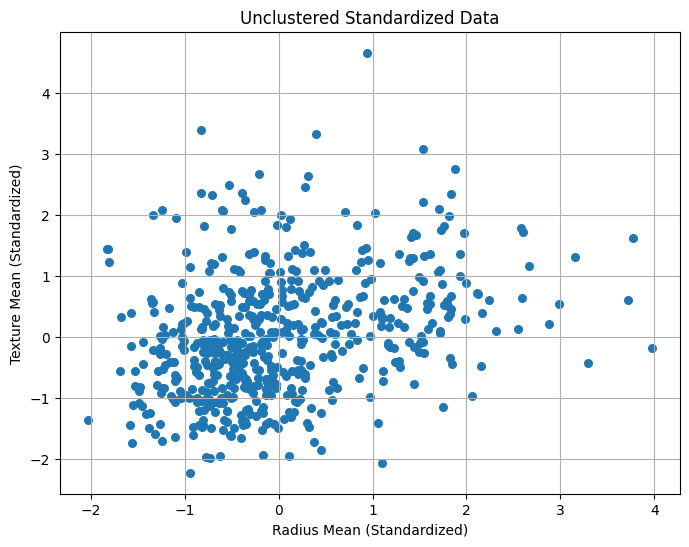

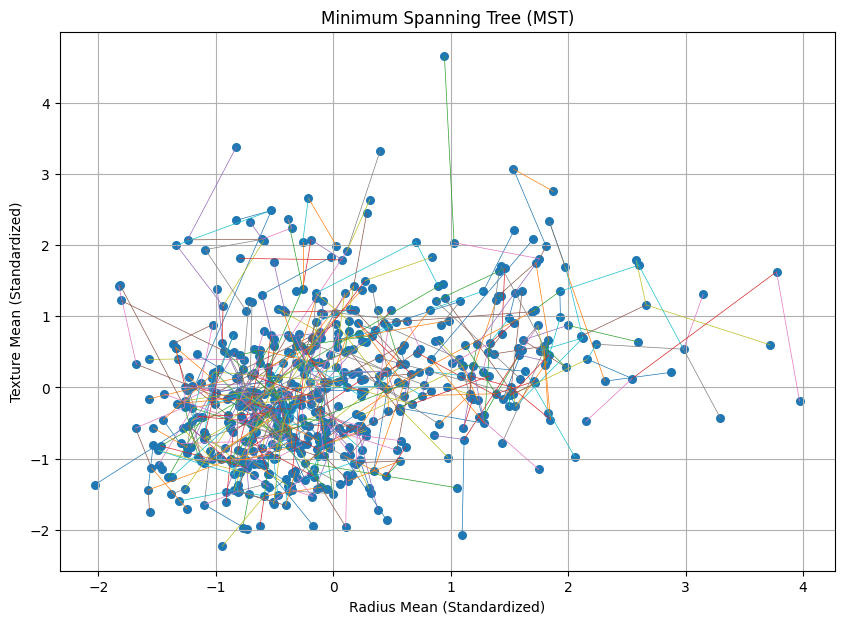

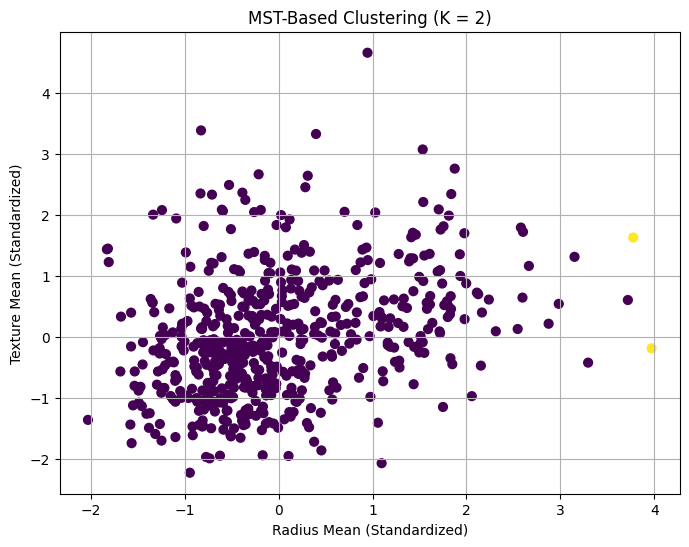

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.datasets import load_breast_cancer

# Select two features for visualization
feature_x = "mean radius"
feature_y = "mean texture"

# Get feature indices
x_index = X.columns.get_loc(feature_x)
y_index = X.columns.get_loc(feature_y)

# Get standardized feature values
x_values = X_scaled[:, x_index]
y_values = X_scaled[:, y_index]


# =========================================================
# PLOT 1: UNCLUSTERED DATA
# =========================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    x_values,
    y_values,
    s=30
)

plt.xlabel("Radius Mean (Standardized)")
plt.ylabel("Texture Mean (Standardized)")
plt.title("Unclustered Standardized Data")

plt.grid(True)
plt.show()


# =========================================================
# PLOT 2: MST OVERLAY
# =========================================================

plt.figure(figsize=(10, 7))

# Plot data points
plt.scatter(
    x_values,
    y_values,
    s=30
)

# Draw MST edges
for u, v, data in mst.edges(data=True):

    plt.plot(
        [x_values[u], x_values[v]],
        [y_values[u], y_values[v]],
        linewidth=0.5
    )

plt.xlabel("Radius Mean (Standardized)")
plt.ylabel("Texture Mean (Standardized)")
plt.title("Minimum Spanning Tree (MST)")

plt.grid(True)
plt.show()


# =========================================================
# PLOT 3: FINAL MST CLUSTERS
# =========================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    x_values,
    y_values,
    c=cluster_labels,
    s=40
)

plt.xlabel("Radius Mean (Standardized)")
plt.ylabel("Texture Mean (Standardized)")
plt.title("MST-Based Clustering (K = 2)")

plt.grid(True)
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.